# 02 — Correlação

Relação entre o clima de cada município e a área colhida de cada cultura. Usa a correlação de **Spearman**, que não exige relação linear e é menos sensível a valores extremos (a área tem distribuição muito assimétrica).

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('../data/processed/dataset_municipios.csv')
culturas = ['Café', 'Cana-de-açúcar', 'Feijão', 'Laranja', 'Milho', 'Soja']
clima = ['temp_media', 'temp_min', 'chuva_anual', 'umidade', 'radiacao', 'amplitude_termica', 'contraste_chuva', 'chuva_seca']
df[clima].describe().round(2)

,temp_media,temp_min,chuva_anual,umidade,radiacao,amplitude_termica,contraste_chuva,chuva_seca
count,1576.00,1576.00,1576.00,1576.00,1576.00,1576.00,1576.00,1576.00
mean,22.08,4.91,1199.44,73.17,18.30,4.94,5.40,0.81
std,1.68,3.03,155.17,4.87,1.03,1.17,1.06,0.54
min,18.53,-1.90,679.36,56.59,14.81,1.85,0.99,0.03
25%,20.85,2.73,1154.19,70.18,17.50,4.12,4.76,0.42
50%,22.05,4.50,1227.24,73.27,18.41,4.80,5.68,0.62
75%,23.51,6.55,1303.94,76.74,19.04,6.00,6.18,1.10
max,26.44,18.68,1804.34,85.53,21.68,8.09,7.32,2.98


## Correlação entre as variáveis de clima (redundância)

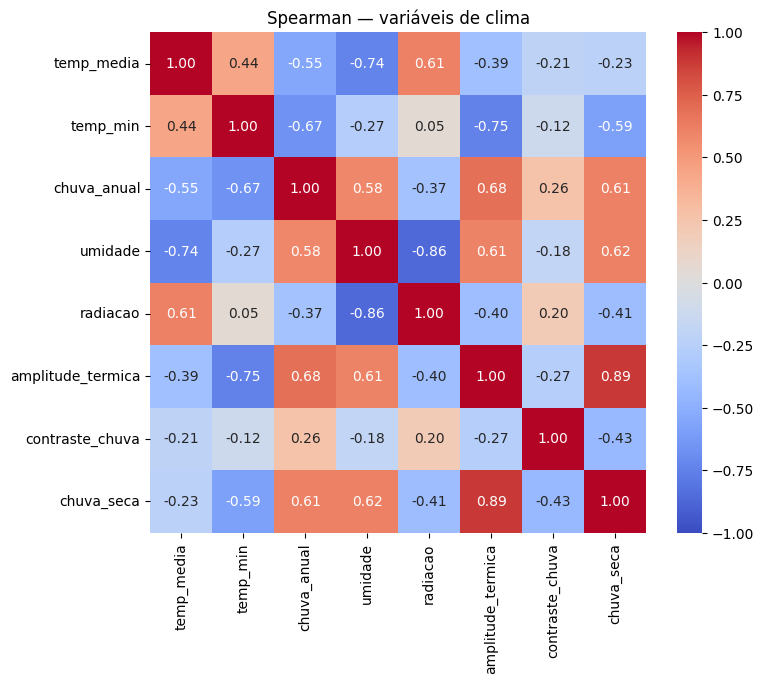

In [2]:
corr_clima = df[clima].corr(method='spearman')
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr_clima, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Spearman — variáveis de clima')
plt.savefig('../data/processed/matriz_correlacao_clima.png', bbox_inches='tight'); plt.show()

## Clima x área colhida de cada cultura

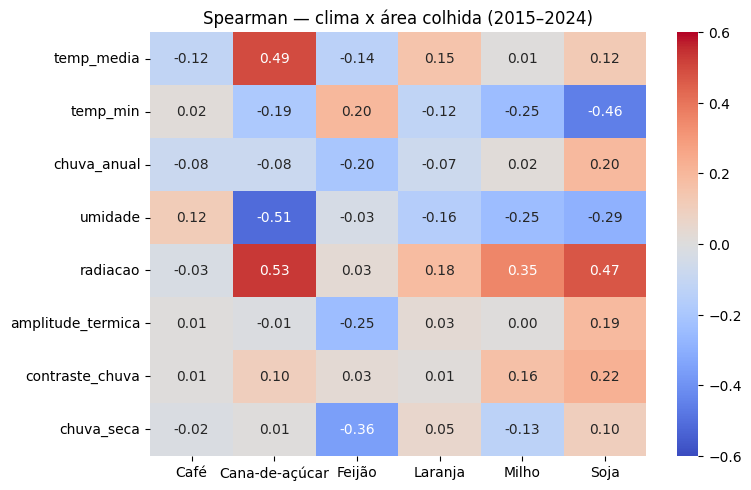

,Café,Cana-de-açúcar,Feijão,Laranja,Milho,Soja
temp_media,-0.12,0.49,-0.14,0.15,0.01,0.12
temp_min,0.02,-0.19,0.20,-0.12,-0.25,-0.46
chuva_anual,-0.08,-0.08,-0.20,-0.07,0.02,0.20
umidade,0.12,-0.51,-0.03,-0.16,-0.25,-0.29
radiacao,-0.03,0.53,0.03,0.18,0.35,0.47
amplitude_termica,0.01,-0.01,-0.25,0.03,0.00,0.19
contraste_chuva,0.01,0.10,0.03,0.01,0.16,0.22
chuva_seca,-0.02,0.01,-0.36,0.05,-0.13,0.10


In [3]:
corr_cult = pd.DataFrame({c: df[clima].apply(lambda s: s.corr(df['area_' + c], method='spearman')) for c in culturas})
plt.figure(figsize=(8, 5.5))
sns.heatmap(corr_cult, annot=True, fmt='.2f', cmap='coolwarm', vmin=-0.6, vmax=0.6)
plt.title('Spearman — clima x área colhida (2015–2024)')
plt.savefig('../data/processed/matriz_correlacao_culturas.png', bbox_inches='tight'); plt.show()
corr_cult.round(2).to_csv('../data/processed/correlacao_clima_culturas.csv')
corr_cult.round(2)

## Leitura

Valores próximos de 0 indicam que a variável não se relaciona de forma monotônica com a área da cultura. A área colhida também depende do tamanho do município, do solo, do relevo e do mercado. Por isso as correlações esperadas são moderadas, e o modelo de classificação do notebook 04 combina várias variáveis ao mesmo tempo.